# BI10 Round 02 — Challenge 1 | Financial Health Score V2
**4.1** Eligibility · **4.2** Two-pillar score + group-median imputation · **4.3A** Coverage/Distribution · **4.3B** Masked Validation/Sensitivity/Cap.

**Input:** `C1_STEP3_OUTPUT/run_*/tables/03_customer_feature_mart.csv` (read-only). **Output:** `C1_STEP4_V2_OUTPUT/run_*/` (new files only). **No DuckDB database write, no modification of V1.**

**Methodological boundary:** A1/A2 are proxies until income periodicity is verified; P1 is a resolved-status denominator proxy, **not** a measured DPD/default probability. WO is an adverse observed status, not a forward-looking default label. FHS from imputation is an **estimated analytical score**, never equivalent in evidence strength to FULL.

## 01 — Cấu hình & đường dẫn

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from uuid import uuid4
import os, json, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

S4_MART_OVERRIDE = None  # Optional: exact 03_customer_feature_mart.csv path
S4_OUTPUT_OVERRIDE = None  # Optional: output parent folder
CFG = {
    'version': 'BI10_FHS_V2.0', 'capacity_weight': .50, 'a1_weight': .80,
    'odsr_good': .10, 'odsr_stress': .50,
    'a2_q_low': .10, 'a2_q_high': .90,
    'prior_cases': 5., 'payment_risk_scale': 1., 'wo_cap': 50.,
    'min_group_ref': 200, 'income_spread_warning': 1.50,
    'imputation': 'GROUP_MEDIAN', 'mask_holdout_fraction': .20,
    'mask_seed': 20261018, 'payment_maturity_confirmed': False,
    'diagnostic_score_bands': [0,20,40,60,80,100],
}
assert 0 < CFG['capacity_weight'] < 1 and 0 < CFG['a1_weight'] < 1
assert 0 <= CFG['odsr_good'] < CFG['odsr_stress'] and CFG['prior_cases'] > 0
roots = list(dict.fromkeys([Path.cwd().resolve(), Path.cwd().resolve().parent, Path.cwd().resolve().parent.parent]))
if S4_MART_OVERRIDE:
    MART = Path(S4_MART_OVERRIDE).expanduser().resolve()
else:
    candidates = [p.resolve() for root in roots for sub in ['', 'BI10_ROUND02_DATASET/']
                  for p in (root / sub / 'C1_STEP3_OUTPUT').glob('run_*/tables/03_customer_feature_mart.csv')]
    candidates = sorted(set(candidates), key=lambda x:x.stat().st_mtime, reverse=True)
    if not candidates: raise FileNotFoundError('Không tìm thấy 03_customer_feature_mart.csv. Khai báo S4_MART_OVERRIDE.')
    MART = candidates[0]
if not MART.is_file(): raise FileNotFoundError(MART)
base = Path(S4_OUTPUT_OVERRIDE).resolve() if S4_OUTPUT_OVERRIDE else MART.parents[3]
OUT = base / 'C1_STEP4_V2_OUTPUT' / ('run_' + datetime.now().strftime('%Y%m%d_%H%M%S') + '_' + uuid4().hex[:6])
TABLES, FIGURES = OUT/'tables', OUT/'figures'
TABLES.mkdir(parents=True, exist_ok=False)
FIGURES.mkdir()
print('FEATURE MART:', MART, '\nOUTPUT:', OUT, '\nVERSION:', CFG['version'])

FEATURE MART: C:\Users\nguyen\Desktop\BI_r2\BI10_ROUND02_DATASET\C1_STEP3_OUTPUT\run_20261018_091425_849a72\tables\03_customer_feature_mart.csv 
OUTPUT: C:\Users\nguyen\Desktop\BI_r2\BI10_ROUND02_DATASET\C1_STEP4_V2_OUTPUT\run_20261018_113802_840b33 
VERSION: BI10_FHS_V2.0


## 02 — Đọc Feature Mart và khóa schema

In [2]:
REQ = [
 'SKP_CLIENT','A1_ODSR_IF_INCOME_MONTHLY','A2_RESIDUAL_IF_INCOME_MONTHLY',
 'P1_DUE_RATE_RESOLVED_PROXY','P2_DUE_FLAG_BREADTH_AMONG_AFFECTED',
 'P3_WRITTEN_OFF_HISTORY','income_candidate','active_annuity_known',
 'n_active_cases_with_annuity','n_active_cases_missing_annuity',
 'n_payment_observable_resolved_proxy','n_due_resolved_proxy',
 'n_written_off_cases','n_signed_cases','n_integrity_failed_cases',
 'income_period_monthly_confirmed'
]
OPT = ['income_source_product','income_source_application_time','income_spread_across_cases']
header = pd.read_csv(MART, nrows=0).columns.tolist()
missing = sorted(set(REQ)-set(header))
if missing: raise ValueError('Feature Mart thiếu cột bắt buộc: '+str(missing))
COLS = REQ + [c for c in OPT if c in header]
df = pd.read_csv(MART, usecols=COLS, dtype={'SKP_CLIENT':'string'}, low_memory=False)
if df.SKP_CLIENT.isna().any() or df.SKP_CLIENT.str.strip().eq('').any() or df.SKP_CLIENT.duplicated().any():
    raise ValueError('SKP_CLIENT trống hoặc bị trùng. Dừng trước scoring.')
for c in REQ:
    if c not in ('SKP_CLIENT','income_period_monthly_confirmed'):
        df[c] = pd.to_numeric(df[c], errors='coerce')
if 'income_spread_across_cases' in df: df['income_spread_across_cases'] = pd.to_numeric(df['income_spread_across_cases'], errors='coerce')
df['PRODUCT_CONTEXT'] = (df['income_source_product'].astype('string').str.strip().str.upper()
                         if 'income_source_product' in df else pd.Series(pd.NA,index=df.index,dtype='string'))
df['PRODUCT_CONTEXT'] = df['PRODUCT_CONTEXT'].replace({'':'UNKNOWN','NAN':'UNKNOWN','NONE':'UNKNOWN'})
dates = pd.to_datetime(df['income_source_application_time'], errors='coerce') if 'income_source_application_time' in df else pd.Series(pd.NaT,index=df.index)
df['COHORT_YEAR'] = dates.dt.year.astype('Int64')
monthly = df['income_period_monthly_confirmed'].astype('string').str.lower().str.strip()
df['INCOME_MONTHLY_CONFIRMED'] = monthly.isin(['true','1','yes','y'])
print('Khách hàng:', f'{len(df):,}', '| Cột gốc sử dụng:',len(COLS))
display(pd.DataFrame({'INPUT_COLUMN':COLS,'PURPOSE':['Identity' if c=='SKP_CLIENT' else 'Feature/quality input' for c in COLS]}).head(10))

Khách hàng: 1,000,528 | Cột gốc sử dụng: 19


,INPUT_COLUMN,PURPOSE
0,SKP_CLIENT,Identity
1,A1_ODSR_IF_INCOME_MONTHLY,Feature/quality input
2,A2_RESIDUAL_IF_INCOME_MONTHLY,Feature/quality input
3,P1_DUE_RATE_RESOLVED_PROXY,Feature/quality input
4,P2_DUE_FLAG_BREADTH_AMONG_AFFECTED,Feature/quality input
5,P3_WRITTEN_OFF_HISTORY,Feature/quality input
6,income_candidate,Feature/quality input
7,active_annuity_known,Feature/quality input
8,n_active_cases_with_annuity,Feature/quality input
9,n_active_cases_missing_annuity,Feature/quality input


## 03 — 4.1: Kiểm toán eligibility cho từng trụ cột

In [3]:
n_ok = df['n_active_cases_with_annuity'].fillna(0)
n_miss = df['n_active_cases_missing_annuity'].fillna(0)
n_active = n_ok + n_miss
n_obs = df['n_payment_observable_resolved_proxy'].fillna(0)
n_due = df['n_due_resolved_proxy'].fillna(0)
n_wo = df['n_written_off_cases'].fillna(0)
n_signed = df['n_signed_cases'].fillna(0)
integrity = df['n_integrity_failed_cases'].fillna(0)
income = df['income_candidate']; annuity = df['active_annuity_known']
a1 = df['A1_ODSR_IF_INCOME_MONTHLY']; a2 = df['A2_RESIDUAL_IF_INCOME_MONTHLY']
p1 = df['P1_DUE_RATE_RESOLVED_PROXY']; p3 = df['P3_WRITTEN_OFF_HISTORY']
valid_counts = ((n_ok>=0)&(n_miss>=0)&(n_obs>=0)&(n_due>=0)&(n_due<=n_obs)&(n_wo>=0)&(n_signed>=0))
no_active = (n_active==0)&(n_miss==0)
active_known = (n_active>0)&(n_miss==0)&(n_ok==n_active)&(annuity>0)
expected_annuity = annuity.where(~no_active, 0)
expected_a1 = expected_annuity / income.where(income>0)
expected_a2 = income - expected_annuity
consistent_capacity = (np.isclose(a1, expected_a1, rtol=1e-6,atol=1e-7,equal_nan=False)&
                       np.isclose(a2, expected_a2,rtol=1e-6,atol=.01,equal_nan=False))
consistent_payment = np.isclose(p1, n_due/n_obs.where(n_obs>0),rtol=1e-6,atol=1e-7,equal_nan=False)
consistent_wo = ((p3.isin([0,1]))&(p3==(n_wo>0).astype(int)))
cap_ok = ((integrity==0)&valid_counts&(income>0)&np.isfinite(income)&
          (no_active|active_known)&consistent_capacity&(a1>=0)&np.isfinite(a1)&np.isfinite(a2))
pay_ok = ((integrity==0)&valid_counts&(n_signed>0)&(n_obs>0)&consistent_payment&
          p1.between(0,1)&consistent_wo)
wo_observed = (n_signed>0)&(n_wo>0)
df['CAPACITY_OBSERVED'] = cap_ok.to_numpy(dtype=bool)
df['PAYMENT_OBSERVED'] = pay_ok.to_numpy(dtype=bool)
df['WRITTEN_OFF_OBSERVED'] = wo_observed.to_numpy(dtype=bool)
df['NO_ACTIVE_INTERNAL_DEBT'] = no_active.to_numpy(dtype=bool)
df['ACTIVE_DEBT_INCOMPLETE'] = (n_miss>0).to_numpy(dtype=bool)
df['A3_ACTIVE_CASE_COUNT'] = n_active.astype('int32')
df['ELIGIBILITY_STATUS'] = np.select([cap_ok&pay_ok,cap_ok,pay_ok],
                      ['FULL','PAYMENT_IMPUTED','CAPACITY_IMPUTED'],default='NO_EVIDENCE')
display(df.ELIGIBILITY_STATUS.value_counts(dropna=False).rename_axis('STATUS').reset_index(name='CUSTOMERS'))
print('No Active + Capacity observed:', int((cap_ok&no_active).sum()),
      '| Written off observed:',int(wo_observed.sum()))

,STATUS,CUSTOMERS
0,FULL,471605
1,NO_EVIDENCE,237863
2,CAPACITY_IMPUTED,171969
3,PAYMENT_IMPUTED,119091


No Active + Capacity observed: 213346 | Written off observed: 13319


## 04 — 4.1: Kiểm tra điểm sai định nghĩa và cảnh báo dữ liệu

In [4]:
# Khác với điểm kém: dấu hiệu thiếu bằng chứng được ghi riêng, không trừ điểm.
df['DATA_WARNINGS'] = ''
warns = {
    'INCOME_PERIOD_UNCONFIRMED': ~df.INCOME_MONTHLY_CONFIRMED,
    'PAYMENT_MATURITY_UNCONFIRMED': pd.Series(not CFG['payment_maturity_confirmed'],index=df.index),
    'NO_OBSERVED_ACTIVE_DEBT': df.NO_ACTIVE_INTERNAL_DEBT,
    'ACTIVE_ANNUITY_INCOMPLETE': df.ACTIVE_DEBT_INCOMPLETE,
    'INCOME_MISSING_OR_INVALID': ~(income>0),
    'CASE_INTEGRITY_ISSUE': integrity>0,
    'PAYMENT_DENOMINATOR_UNAVAILABLE': n_obs==0,
}
if 'income_spread_across_cases' in df:
    warns['INCOME_VARIES_ACROSS_CASES'] = df.income_spread_across_cases>CFG['income_spread_warning']
for name,mask in warns.items():
    df['DATA_WARNINGS'] = df.DATA_WARNINGS + np.where(mask.fillna(False),name+';', '')
df['DATA_WARNINGS'] = df.DATA_WARNINGS.str.rstrip(';')
quality = pd.DataFrame([{'CHECK':k,'CUSTOMERS':int(v.fillna(False).sum()),'PCT':round(100*v.fillna(False).mean(),2)} for k,v in warns.items()])
quality.to_csv(TABLES/'01_data_quality_audit.csv',index=False,encoding='utf-8-sig')
display(quality)
assert not (df.CAPACITY_OBSERVED & df.ACTIVE_DEBT_INCOMPLETE).any()
assert not (df.PAYMENT_OBSERVED & (n_obs==0)).any()

,CHECK,CUSTOMERS,PCT
0,INCOME_PERIOD_UNCONFIRMED,1000528,100.00
1,PAYMENT_MATURITY_UNCONFIRMED,1000528,100.00
2,NO_OBSERVED_ACTIVE_DEBT,395942,39.57
3,ACTIVE_ANNUITY_INCOMPLETE,227234,22.71
4,INCOME_MISSING_OR_INVALID,182598,18.25
5,CASE_INTEGRITY_ISSUE,0,0.00
6,PAYMENT_DENOMINATOR_UNAVAILABLE,356954,35.68
7,INCOME_VARIES_ACROSS_CASES,337351,33.72


## 05 — 4.2: Hiệu chuẩn tham số theo mẫu hợp lệ

In [5]:
ci = df.CAPACITY_OBSERVED.to_numpy(bool)
pi = df.PAYMENT_OBSERVED.to_numpy(bool)
a2_ref = a2.loc[ci].to_numpy(float)
if len(a2_ref)<30: raise ValueError('Ít hơn 30 hồ sơ Capacity để hiệu chuẩn A2.')
A2_LO, A2_HI = np.quantile(a2_ref,[CFG['a2_q_low'],CFG['a2_q_high']])
if not np.isfinite(A2_LO) or not np.isfinite(A2_HI) or A2_HI<=A2_LO:
    raise ValueError('Không hiệu chuẩn được phân vị A2.')
DUE_EVENTS = int(n_due.loc[pi].sum())
DUE_OBS = int(n_obs.loc[pi].sum())
if DUE_OBS<=0 or DUE_EVENTS<=0 or DUE_EVENTS>=DUE_OBS:
    raise ValueError('Tỷ lệ DUE nền không hợp lệ (0 hoặc 100%).')
P0 = DUE_EVENTS/DUE_OBS
CAL = {'a2_p10':float(A2_LO),'a2_p90':float(A2_HI),'payment_prior_due_rate':float(P0),
       'payment_due_cases':DUE_EVENTS,'payment_observable_cases':DUE_OBS,
       'capacity_reference_clients':int(ci.sum()),'payment_reference_clients':int(pi.sum())}
display(pd.DataFrame([CAL]).T.rename(columns={0:'VALUE'}))

,VALUE
a2_p10,6.220000e+06
a2_p90,1.709500e+07
payment_prior_due_rate,1.944106e-02
payment_due_cases,3.961900e+04
payment_observable_cases,2.037903e+06
capacity_reference_clients,5.906960e+05
payment_reference_clients,6.435740e+05


## 06 — 4.2: Hàm score độc lập và có kiểm thử đơn điệu

In [6]:
def a1_score(x,good=None,stress=None):
    good = CFG['odsr_good'] if good is None else good
    stress = CFG['odsr_stress'] if stress is None else stress
    return np.clip(100*(stress-np.asarray(x,float))/(stress-good),0,100)

def a2_score(x):
    return np.clip(100*(np.asarray(x,float)-A2_LO)/(A2_HI-A2_LO),0,100)

def p1_score(d,n,k=None,scale=None):
    k = CFG['prior_cases'] if k is None else k
    scale = CFG['payment_risk_scale'] if scale is None else scale
    posterior = (np.asarray(d,float)+k*P0)/(np.asarray(n,float)+k)
    return 100/(1+posterior/(P0*scale))

def wo_cap(score,observed,limit=None):
    limit = CFG['wo_cap'] if limit is None else limit
    return np.where(np.asarray(observed,bool),np.minimum(score,limit),score)

assert np.all(np.diff(a1_score(np.linspace(0,1,101)))<=1e-10)
assert np.all(np.diff(a2_score(np.linspace(A2_LO-1,A2_HI+1,101)))>=-1e-10)
assert np.all(np.diff(p1_score(np.arange(11),np.full(11,10)))<=1e-10)
assert np.all(wo_cap(np.array([20.,70.]),[True,True]) <= [20.,70.])
print('PASS: A1 giảm theo ODSR; A2 tăng theo residual; P1 giảm theo DUE; cap không làm tăng điểm.')

PASS: A1 giảm theo ODSR; A2 tăng theo residual; P1 giảm theo DUE; cap không làm tăng điểm.


## 07 — 4.2: Tạo Capacity/Payment quan sát được

In [7]:
N = len(df)
C = np.full(N,np.nan)
P = np.full(N,np.nan)
SA1 = np.full(N,np.nan)
SA2 = np.full(N,np.nan)
SP1 = np.full(N,np.nan)
SA1[ci] = a1_score(a1.to_numpy(float)[ci])
SA2[ci] = a2_score(a2.to_numpy(float)[ci])
SP1[pi] = p1_score(n_due.to_numpy(float)[pi],n_obs.to_numpy(float)[pi])
C[ci] = CFG['a1_weight']*SA1[ci]+(1-CFG['a1_weight'])*SA2[ci]
P[pi] = SP1[pi]
df['A1_SCORE'] = SA1; df['A2_SCORE'] = SA2; df['P1_SCORE'] = SP1
df['CAPACITY_SCORE'] = C; df['PAYMENT_SCORE'] = P
print('Capacity:',np.isfinite(C).sum(),'| Payment:',np.isfinite(P).sum(),'| Fully observed:',(ci&pi).sum())
assert np.isfinite(C[ci]).all() and np.isfinite(P[pi]).all()
assert (np.isnan(C[~ci])).all() and (np.isnan(P[~pi])).all()

Capacity: 590696 | Payment: 643574 | Fully observed: 471605


## 08 — 4.2: Ước lượng median theo Product/Cohort và fallback

In [8]:
# Dữ liệu PRODUCT_CONTEXT/COHORT_YEAR có thể không tồn tại cho người thiếu Capacity.
# Khi thiếu khóa nhóm hoặc không đủ min_group_ref, dùng global median; KHÔNG gán nhóm giả.
def reference_medians(reference, col, min_n):
    good = reference.loc[reference[col].notna(), ['PRODUCT_CONTEXT','COHORT_YEAR',col]].copy()
    if good.empty: raise ValueError('Không có điểm tham chiếu cho '+col)
    overall = float(good[col].median())
    product = good.dropna(subset=['PRODUCT_CONTEXT']).groupby('PRODUCT_CONTEXT')[col].agg(['median','count'])
    product = product.loc[product['count']>=min_n,'median']
    duo = good.dropna(subset=['PRODUCT_CONTEXT','COHORT_YEAR']).groupby(['PRODUCT_CONTEXT','COHORT_YEAR'])[col].agg(['median','count'])
    duo = duo.loc[duo['count']>=min_n,'median']
    return {'global':overall,'product':product,'product_year':duo}

def fill_from_reference(target, refs, key_product='PRODUCT_CONTEXT', key_year='COHORT_YEAR'):
    values = np.full(len(target),refs['global'],float)
    source = np.full(len(target),'GLOBAL_MEDIAN',dtype=object)
    prod = target[key_product].astype('string')
    py = pd.MultiIndex.from_frame(target[[key_product,key_year]])
    pvals = prod.map(refs['product']).to_numpy(dtype=float,na_value=np.nan)
    gvals = refs['product_year'].reindex(py).to_numpy(dtype=float)
    pm = np.isfinite(pvals)
    values[pm] = pvals[pm]; source[pm] = 'PRODUCT_MEDIAN'
    gm = np.isfinite(gvals)
    values[gm] = gvals[gm]; source[gm] = 'PRODUCT_COHORT_MEDIAN'
    return values, source

REF_C = reference_medians(df,'CAPACITY_SCORE',CFG['min_group_ref'])
REF_P = reference_medians(df,'PAYMENT_SCORE',CFG['min_group_ref'])
print('Median toàn danh mục:',{'Capacity':round(REF_C['global'],2),'Payment':round(REF_P['global'],2)})
print('Số nhóm Product/Cohort đủ mẫu:',len(REF_C['product_year']),len(REF_P['product_year']))

Median toàn danh mục: {'Capacity': 85.11, 'Payment': 58.33}
Số nhóm Product/Cohort đủ mẫu: 50 50


## 09 — 4.2: Tính FHS đầy đủ + FHS ước lượng cho một trụ cột thiếu

In [9]:
def combine_scores(cap,pay,has_wo,capacity_weight=None,wo_limit=None):
    w = CFG['capacity_weight'] if capacity_weight is None else capacity_weight
    before = w*np.asarray(cap,float)+(1-w)*np.asarray(pay,float)
    return before, wo_cap(before,has_wo,wo_limit)

m_c = ~ci & pi
m_p = ci & ~pi
if CFG['imputation']=='GROUP_MEDIAN':
    fillc, src_c = fill_from_reference(df.loc[m_c], REF_C)
    fillp, src_p = fill_from_reference(df.loc[m_p], REF_P)
elif CFG['imputation']=='GLOBAL_MEDIAN':
    fillc = np.full(m_c.sum(),REF_C['global']); src_c = np.full(m_c.sum(),'GLOBAL_MEDIAN')
    fillp = np.full(m_p.sum(),REF_P['global']); src_p = np.full(m_p.sum(),'GLOBAL_MEDIAN')
else:
    raise ValueError('CFG.imputation chỉ nhận GROUP_MEDIAN hoặc GLOBAL_MEDIAN; REWEIGHT được kiểm định riêng.')
C_USE, P_USE = C.copy(),P.copy()
C_USE[m_c] = fillc; P_USE[m_p] = fillp
IMP_SOURCE = np.full(N,'OBSERVED_BOTH',dtype=object)
IMP_SOURCE[m_c] = src_c; IMP_SOURCE[m_p] = src_p
IMP_SOURCE[~(ci|pi)] = 'NO_EVIDENCE'
WO = df.WRITTEN_OFF_OBSERVED.to_numpy(bool)
FHS_BASE, FHS = combine_scores(C_USE,P_USE,WO)
assert np.isnan(FHS[~(ci|pi)]).all()
# Bounds use the theoretical 0–100 for an unknown pillar, not false 95% confidence intervals.
w = CFG['capacity_weight']
LO = np.where(ci&pi,FHS,np.where(m_p,w*C,np.where(m_c,(1-w)*P,np.nan)))
HI = np.where(ci&pi,FHS,np.where(m_p,w*C+(1-w)*100,np.where(m_c,w*100+(1-w)*P,np.nan)))
LO = wo_cap(LO,WO); HI = wo_cap(HI,WO)
CAP_IMPACT = np.where(np.isfinite(FHS),FHS-FHS_BASE,np.nan)
for col,arr in [('CAPACITY_USED',C_USE),('PAYMENT_USED',P_USE),('FINANCIAL_HEALTH_SCORE',FHS),
                ('FHS_BEFORE_WO_CAP',FHS_BASE),('WO_CAP_IMPACT',CAP_IMPACT),
                ('FHS_THEORETICAL_LOWER',LO),('FHS_THEORETICAL_UPPER',HI)]: df[col] = arr
df['IMPUTATION_SOURCE'] = IMP_SOURCE
df['SCORE_EVIDENCE_FLAG'] = df.ELIGIBILITY_STATUS
print(df.groupby('SCORE_EVIDENCE_FLAG').FINANCIAL_HEALTH_SCORE.agg(['size','count','mean']).round(2))
assert np.allclose(FHS[ci&pi],wo_cap(w*C[ci&pi]+(1-w)*P[ci&pi],WO[ci&pi]))

                       size   count   mean
SCORE_EVIDENCE_FLAG                       
CAPACITY_IMPUTED     171969  171969  72.08
FULL                 471605  471605  68.58
NO_EVIDENCE          237863       0    NaN
PAYMENT_IMPUTED      119091  119091  67.22


## 10 — 4.2: Reason Codes, phân rã điểm và kiểm toán

In [10]:
df['REASON_CODES'] = ''
reasons = {
 'HIGH_OBSERVED_DEBT_BURDEN': ci & (SA1<40),
 'LOW_RESIDUAL_INCOME_PROXY': ci & (SA2<30),
 'PAYMENT_DUE_RECORDED': pi & (n_due.to_numpy(float)>0),
 'NO_DUE_RECORDED_IN_OBSERVABLE_PROXY': pi & (n_due.to_numpy(float)==0),
 'WRITTEN_OFF_OBSERVED': WO,
 'CAPACITY_ESTIMATED_FROM_MEDIAN': m_c,
 'PAYMENT_ESTIMATED_FROM_MEDIAN': m_p,
}
for label,flag in reasons.items():
    df['REASON_CODES'] += np.where(flag,label+';', '')
df['REASON_CODES'] = df.REASON_CODES.str.rstrip(';')
df['CONTRIBUTION_CAPACITY'] = w*C_USE
df['CONTRIBUTION_PAYMENT'] = (1-w)*P_USE
df['SCORING_VERSION'] = CFG['version']
observed_count = ci.astype(int)+pi.astype(int)
df['PILLAR_COVERAGE_PCT'] = observed_count*50
# Payment maturity and income period are unverified; 100% pillar coverage != 100% evidence confidence.
assert np.nanmin(FHS)>=0 and np.nanmax(FHS)<=100
assert np.allclose((df.CONTRIBUTION_CAPACITY+df.CONTRIBUTION_PAYMENT+df.WO_CAP_IMPACT)[np.isfinite(FHS)],FHS[np.isfinite(FHS)])
assert (FHS[WO & np.isfinite(FHS)]<=CFG['wo_cap']+1e-9).all()
assert (LO[np.isfinite(FHS)]<=FHS[np.isfinite(FHS)]+1e-8).all()
assert (HI[np.isfinite(FHS)]>=FHS[np.isfinite(FHS)]-1e-8).all()
print('PASS: 0–100, FHS breakdown, imputation flags, theoretical bounds, Written-off cap.')

PASS: 0–100, FHS breakdown, imputation flags, theoretical bounds, Written-off cap.


## 11 — 4.2: Xuất dataset khách hàng và cấu hình phiên bản

In [11]:
EXPORT = ['SKP_CLIENT','SCORE_EVIDENCE_FLAG','CAPACITY_SCORE','PAYMENT_SCORE',
          'CAPACITY_USED','PAYMENT_USED','FINANCIAL_HEALTH_SCORE','FHS_BEFORE_WO_CAP',
          'WO_CAP_IMPACT','FHS_THEORETICAL_LOWER','FHS_THEORETICAL_UPPER',
          'PILLAR_COVERAGE_PCT','IMPUTATION_SOURCE','A1_SCORE','A2_SCORE','P1_SCORE',
          'A1_ODSR_IF_INCOME_MONTHLY','A2_RESIDUAL_IF_INCOME_MONTHLY',
          'P1_DUE_RATE_RESOLVED_PROXY','P2_DUE_FLAG_BREADTH_AMONG_AFFECTED',
          'P3_WRITTEN_OFF_HISTORY','A3_ACTIVE_CASE_COUNT',
          'CAPACITY_OBSERVED','PAYMENT_OBSERVED','WRITTEN_OFF_OBSERVED',
          'NO_ACTIVE_INTERNAL_DEBT','ACTIVE_DEBT_INCOMPLETE','INCOME_MONTHLY_CONFIRMED',
          'PRODUCT_CONTEXT','COHORT_YEAR','CONTRIBUTION_CAPACITY','CONTRIBUTION_PAYMENT',
          'REASON_CODES','DATA_WARNINGS','SCORING_VERSION']
TARGET = TABLES/'02_customer_fhs_v2.csv'
df[EXPORT].round(6).to_csv(TARGET,index=False,encoding='utf-8',float_format='%.6f')
params = {**CFG,'source_mart':str(MART),'source_size_bytes':MART.stat().st_size,
          'generated_at_utc':datetime.now(timezone.utc).isoformat(),
          'calibration':CAL, 'median_capacity_global':REF_C['global'],'median_payment_global':REF_P['global']}
(OUT/'scoring_parameters_v2.json').write_text(json.dumps(params,indent=2,ensure_ascii=False),encoding='utf-8')
print('SCORING DATA:',TARGET)
print('ROWS:',f'{len(df):,}','| NUMERIC FHS:',f'{np.isfinite(FHS).sum():,}')
display(df[EXPORT[:11]].head(8))

SCORING DATA: C:\Users\nguyen\Desktop\BI_r2\BI10_ROUND02_DATASET\C1_STEP4_V2_OUTPUT\run_20261018_113802_840b33\tables\02_customer_fhs_v2.csv
ROWS: 1,000,528 | NUMERIC FHS: 762,665


,SKP_CLIENT,SCORE_EVIDENCE_FLAG,CAPACITY_SCORE,PAYMENT_SCORE,CAPACITY_USED,PAYMENT_USED,FINANCIAL_HEALTH_SCORE,FHS_BEFORE_WO_CAP,WO_CAP_IMPACT,FHS_THEORETICAL_LOWER,FHS_THEORETICAL_UPPER
0,***,FULL,90.629885,64.285714,90.629885,64.285714,77.457800,77.457800,0.0,77.457800,77.457800
1,***,FULL,66.527586,70.588235,66.527586,70.588235,68.557911,68.557911,0.0,68.557911,68.557911
2,***,FULL,92.840460,66.666667,92.840460,66.666667,79.753563,79.753563,0.0,79.753563,79.753563
3,***,FULL,88.790805,58.333333,88.790805,58.333333,73.562069,73.562069,0.0,73.562069,73.562069
4,***,CAPACITY_IMPUTED,NaN,64.285714,65.937931,64.285714,65.111823,65.111823,0.0,32.142857,82.142857
5,***,FULL,1.070345,76.190476,1.070345,76.190476,38.630411,38.630411,0.0,38.630411,38.630411
6,***,FULL,80.437701,13.753578,80.437701,13.753578,47.095640,47.095640,0.0,47.095640,47.095640
7,***,FULL,80.754545,78.260870,80.754545,78.260870,79.507708,79.507708,0.0,79.507708,79.507708


## 12 — 4.3A: Coverage Audit (V1 vs V2, theo trạng thái)

In [12]:
cover = (df.groupby('SCORE_EVIDENCE_FLAG',dropna=False).agg(
    N=('SKP_CLIENT','size'), SCORED=('FINANCIAL_HEALTH_SCORE','count'),
    WRITTEN_OFF=('WRITTEN_OFF_OBSERVED','sum'),
    NO_ACTIVE=('NO_ACTIVE_INTERNAL_DEBT','sum')).reset_index())
cover['PCT_CUSTOMERS'] = 100*cover.N/len(df)
cover['PCT_TOTAL_SCORED'] = 100*cover.SCORED/len(df)
cover.to_csv(TABLES/'03_coverage_by_evidence.csv',index=False,encoding='utf-8-sig')
display(cover.round(2))
print('Numeric score coverage:',round(100*np.isfinite(FHS).mean(),2),'% | Not scored:',np.isnan(FHS).sum())
print('Written-off scored:',int((WO&np.isfinite(FHS)).sum()),'/',int(WO.sum()))

,SCORE_EVIDENCE_FLAG,N,SCORED,WRITTEN_OFF,NO_ACTIVE,PCT_CUSTOMERS,PCT_TOTAL_SCORED
0,CAPACITY_IMPUTED,171969,171969,170,91,17.19,17.19
1,FULL,471605,471605,13149,213259,47.14,47.14
2,NO_EVIDENCE,237863,0,0,182505,23.77,0.00
3,PAYMENT_IMPUTED,119091,119091,0,87,11.9,11.90


Numeric score coverage: 76.23 % | Not scored: 237863
Written-off scored: 13319 / 13319


## 12B — 4.3A: Kiểm toán riêng No-Active và nguồn Imputation

In [13]:
impute_audit=(df.groupby(['SCORE_EVIDENCE_FLAG','IMPUTATION_SOURCE'],dropna=False)
              .agg(N=('SKP_CLIENT','size'),MEAN_FHS=('FINANCIAL_HEALTH_SCORE','mean'))
              .reset_index().sort_values(['SCORE_EVIDENCE_FLAG','N'],ascending=[True,False]))
no_active_audit=(df.groupby(['SCORE_EVIDENCE_FLAG','NO_ACTIVE_INTERNAL_DEBT'],dropna=False)
              .agg(N=('SKP_CLIENT','size'),MEAN_CAPACITY=('CAPACITY_SCORE','mean'),
                   MEAN_FHS=('FINANCIAL_HEALTH_SCORE','mean'))
              .reset_index())
impute_audit.to_csv(TABLES/'03b_imputation_fallback_audit.csv',index=False,encoding='utf-8-sig')
no_active_audit.to_csv(TABLES/'03c_no_active_score_audit.csv',index=False,encoding='utf-8-sig')
print('Nguồn median được sử dụng:')
display(impute_audit.round(2))
print('Ảnh hưởng của khách hàng không có hợp đồng Active được quan sát:')
display(no_active_audit.round(2))

Nguồn median được sử dụng:


,SCORE_EVIDENCE_FLAG,IMPUTATION_SOURCE,N,MEAN_FHS
1,CAPACITY_IMPUTED,PRODUCT_COHORT_MEDIAN,171463,72.08
2,CAPACITY_IMPUTED,PRODUCT_MEDIAN,415,72.53
0,CAPACITY_IMPUTED,GLOBAL_MEDIAN,91,63.66
3,FULL,OBSERVED_BOTH,471605,68.58
4,NO_EVIDENCE,NO_EVIDENCE,237863,NaN
5,PAYMENT_IMPUTED,PRODUCT_COHORT_MEDIAN,117154,67.24
6,PAYMENT_IMPUTED,PRODUCT_MEDIAN,1937,65.51


Ảnh hưởng của khách hàng không có hợp đồng Active được quan sát:


,SCORE_EVIDENCE_FLAG,NO_ACTIVE_INTERNAL_DEBT,N,MEAN_CAPACITY,MEAN_FHS
0,CAPACITY_IMPUTED,False,171878,NaN,72.08
1,CAPACITY_IMPUTED,True,91,NaN,63.66
2,FULL,False,258346,74.04,66.87
3,FULL,True,213259,88.05,70.65
4,NO_EVIDENCE,False,55358,NaN,NaN
5,NO_EVIDENCE,True,182505,NaN,NaN
6,PAYMENT_IMPUTED,False,119004,76.19,67.21
7,PAYMENT_IMPUTED,True,87,90.43,74.33


## 13 — 4.3A: Distribution Audit theo FULL/IMPUTED

,STATUS,N,MEAN,STD,MIN,P05,P10,P25,MEDIAN,P75,P90,P95,MAX,WO_CAP_APPLIED
0,CAPACITY_IMPUTED,171969,72.08,5.95,32.62,62.14,65.11,70.75,72.64,75.62,77.85,79.59,87.07,73
1,FULL,471605,68.58,11.06,3.45,45.81,50.00,65.72,71.15,75.62,79.17,81.41,92.65,7809
2,PAYMENT_IMPUTED,119091,67.22,9.47,27.27,47.82,54.27,63.17,69.87,73.55,76.48,79.17,82.14,0


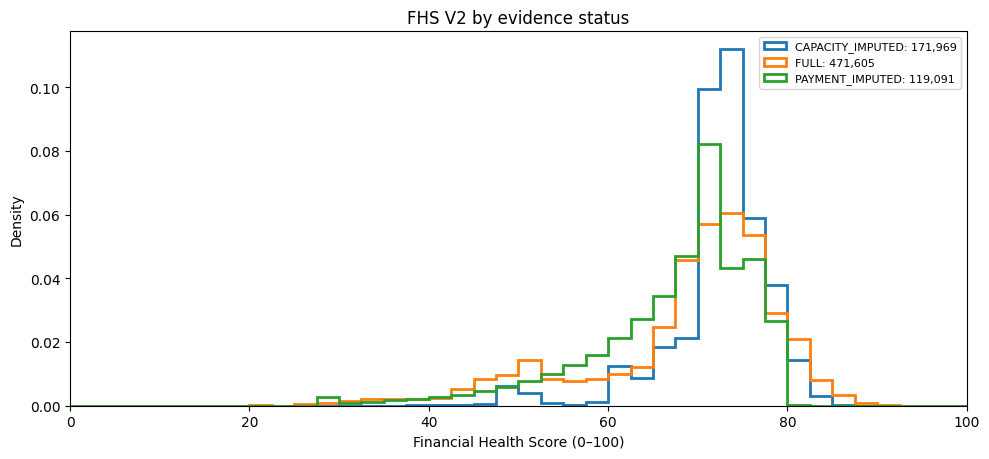

In [14]:
groups=[]
for name,g in df.groupby('SCORE_EVIDENCE_FLAG',dropna=False):
    v=g.FINANCIAL_HEALTH_SCORE.dropna().to_numpy(float)
    if not len(v):continue
    pct=np.percentile(v,[5,10,25,50,75,90,95])
    groups.append({'STATUS':name,'N':len(v),'MEAN':v.mean(),'STD':v.std(),
        'MIN':v.min(),'P05':pct[0],'P10':pct[1],'P25':pct[2],
        'MEDIAN':pct[3],'P75':pct[4],'P90':pct[5],'P95':pct[6],'MAX':v.max(),
        'WO_CAP_APPLIED':int((g.WO_CAP_IMPACT.fillna(0)<-1e-9).sum())})
dist=pd.DataFrame(groups)
dist.to_csv(TABLES/'04_score_distribution.csv',index=False,encoding='utf-8-sig')
display(dist.round(2))
fig,ax=plt.subplots(figsize=(10,4.7))
for name,g in df.groupby('SCORE_EVIDENCE_FLAG'):
    z=g.FINANCIAL_HEALTH_SCORE.dropna()
    if len(z)>0:ax.hist(z,bins=np.linspace(0,100,41),density=True,histtype='step',linewidth=2,label=f'{name}: {len(z):,}')
ax.set(xlim=(0,100),xlabel='Financial Health Score (0–100)',ylabel='Density',title='FHS V2 by evidence status')
ax.legend(fontsize=8);fig.tight_layout()
fig.savefig(FIGURES/'01_score_distribution_by_evidence.png',dpi=170)
plt.show()

## 14 — 4.3A: Audit sản phẩm/cohort và rủi ro selection bias

In [15]:
def group_coverage(keys):
    x = df.groupby(keys,dropna=False).agg(
        N=('SKP_CLIENT','size'),SCORED=('FINANCIAL_HEALTH_SCORE','count'),
        OBS_CAP=('CAPACITY_OBSERVED','sum'),OBS_PAY=('PAYMENT_OBSERVED','sum'),
        MEAN_SCORE=('FINANCIAL_HEALTH_SCORE','mean'),
        WO=('WRITTEN_OFF_OBSERVED','sum')).reset_index()
    x['COVERAGE_PCT']=100*x.SCORED/x.N
    return x
product_audit=group_coverage(['PRODUCT_CONTEXT'])
cohort_audit=group_coverage(['COHORT_YEAR'])
product_audit.to_csv(TABLES/'05_coverage_by_income_source_product.csv',index=False,encoding='utf-8-sig')
cohort_audit.to_csv(TABLES/'06_coverage_by_income_source_cohort.csv',index=False,encoding='utf-8-sig')
display(product_audit.sort_values('N',ascending=False).head(15).round(2))
display(cohort_audit.sort_values('COHORT_YEAR').tail(12).round(2))
print('Lưu ý: PRODUCT_CONTEXT/COHORT_YEAR xuất phát từ hồ sơ thu nhập gần nhất; không phải portfolio-wide product mix.')

,PRODUCT_CONTEXT,N,SCORED,OBS_CAP,OBS_PAY,MEAN_SCORE,WO,COVERAGE_PCT
2,CD,502621,499179,465600,397858,69.98,7980,99.32
6,<NA>,182598,91,0,91,63.66,23,0.05
0,BNPL,139905,90738,3100,90680,72.67,229,64.86
3,CL,107445,106881,82273,106319,64.06,2910,99.48
1,CC,31582,29560,4823,29550,73.49,220,93.6
5,TW,30275,30114,28799,16883,59.45,1370,99.47
4,CW,6102,6102,6101,2193,65.36,587,100.0


,COHORT_YEAR,N,SCORED,OBS_CAP,OBS_PAY,MEAN_SCORE,WO,COVERAGE_PCT
6,2015,2367,2367,2367,2348,58.30,1070,100.0
7,2016,3953,3953,3953,3924,61.38,1196,100.0
8,2017,5225,5225,5224,5206,64.44,1035,100.0
9,2018,6166,6166,6158,6158,65.88,908,100.0
10,2019,7889,7854,7780,7842,67.87,817,99.56
11,2020,8043,8041,7952,8036,68.66,785,99.98
12,2021,10789,10780,10635,10758,67.97,1334,99.92
13,2022,17510,17480,16920,17463,70.10,1677,99.83
14,2023,22318,22172,20673,22096,71.98,823,99.35
15,2024,305209,282956,216421,239056,70.04,1136,92.71


Lưu ý: PRODUCT_CONTEXT/COHORT_YEAR xuất phát từ hồ sơ thu nhập gần nhất; không phải portfolio-wide product mix.


## 14B — 4.3A: Kiểm tra số lượng lịch sử Payment với không ghi nhận DUE

In [16]:
# P1 smoothing tạo sự khác biệt theo N ngay khi DUE=0; phải báo cáo như tác động độ dài lịch sử.
p_cases=pd.DataFrame({'N_PAYMENT_CASES':n_obs[pi].to_numpy(float),
                     'N_DUE':n_due[pi].to_numpy(float),'PAYMENT_SCORE':SP1[pi]})
zero_due=p_cases.loc[p_cases.N_DUE==0].copy()
zero_due['OBSERVED_CASES_BAND']=pd.cut(zero_due.N_PAYMENT_CASES,
                              bins=[0,1,2,5,10,float('inf')],
                              labels=['1','2','3–5','6–10','11+'])
length_audit=(zero_due.groupby('OBSERVED_CASES_BAND',observed=True)
                .agg(N=('PAYMENT_SCORE','size'),MEDIAN_P1=('PAYMENT_SCORE','median'),
                     MEAN_P1=('PAYMENT_SCORE','mean')).reset_index())
length_audit.to_csv(TABLES/'06b_zero_due_payment_case_count_effect.csv',index=False,encoding='utf-8-sig')
display(length_audit.round(2))
print('Giá trị thử P1 khi DUE=0:',
      [(n,round(float(p1_score(0,n)),2)) for n in (1,2,5,10,20)])

,OBSERVED_CASES_BAND,N,MEDIAN_P1,MEAN_P1
0,1,188634,54.55,54.55
1,2,126565,58.33,58.33
2,3–5,199066,64.29,63.58
3,6–10,82098,70.59,70.85
4,11+,10845,77.27,77.81


Giá trị thử P1 khi DUE=0: [(1, 54.55), (2, 58.33), (5, 66.67), (10, 75.0), (20, 83.33)]


## 15 — 4.3B: Masked Validation, tách tập train/holdout theo khách hàng

In [17]:
# Kiểm tra khả năng phục hồi FHS nếu cố ý che đúng một trụ cột.
# Chỉ sử dụng các khách hàng có FULL; median được học trên train, KHÔNG trên holdout.
full_idx=np.flatnonzero(ci&pi)
if len(full_idx)<100: raise ValueError('Cần tối thiểu 100 khách hàng FULL cho masked validation.')
rng=np.random.default_rng(CFG['mask_seed'])
permuted=rng.permutation(full_idx)
nh=int(max(20,round(len(full_idx)*CFG['mask_holdout_fraction'])))
test_idx=permuted[:nh]; train_idx=permuted[nh:]
train=df.iloc[train_idx]
test=df.iloc[test_idx]
train_C=reference_medians(train,'CAPACITY_SCORE',max(5,min(CFG['min_group_ref'],len(train)//10)))
train_P=reference_medians(train,'PAYMENT_SCORE',max(5,min(CFG['min_group_ref'],len(train)//10)))
# Missing Capacity usually implies missing income_source_product/year; mimic that information loss.
test_no_income_context=test[['PRODUCT_CONTEXT','COHORT_YEAR']].copy()
test_no_income_context[['PRODUCT_CONTEXT','COHORT_YEAR']] = pd.NA
C_group,_=fill_from_reference(test_no_income_context,train_C)
P_group,_=fill_from_reference(test,train_P)
C_true=test.CAPACITY_SCORE.to_numpy(float);P_true=test.PAYMENT_SCORE.to_numpy(float)
WO_test=test.WRITTEN_OFF_OBSERVED.to_numpy(bool)
true_score=wo_cap(w*C_true+(1-w)*P_true,WO_test)
print('FULL:',len(full_idx),'| Training:',len(train_idx),'| Holdout:',len(test_idx))

FULL: 471605 | Training: 377284 | Holdout: 94321


## 16 — 4.3B: So sánh Reweighting / Global Median / Group Median

In [18]:
def evaluation(y_true,y_hat):
    err=np.abs(y_true-y_hat)
    bins=CFG['diagnostic_score_bands']
    band_true=np.digitize(y_true,bins[1:-1],right=False)
    band_pred=np.digitize(y_hat,bins[1:-1],right=False)
    rank=pd.Series(y_true).corr(pd.Series(y_hat),method='spearman')
    return dict(MAE=float(err.mean()),P90_ABS_ERROR=float(np.quantile(err,.90)),
        RMSE=float(np.sqrt(np.mean((y_true-y_hat)**2))),
        SPEARMAN=float(rank) if np.isfinite(rank) else np.nan,
        PCT_BAND_CHANGED=float(100*np.mean(band_true!=band_pred)))
rows=[]
for masked in ('CAPACITY','PAYMENT'):
    for method in ('REWEIGHT','GLOBAL_MEDIAN','GROUP_MEDIAN'):
        if masked=='CAPACITY':
            newC={'REWEIGHT':P_true,'GLOBAL_MEDIAN':np.full(len(test),train_C['global']),
                  'GROUP_MEDIAN':C_group}[method]
            pred=wo_cap(w*newC+(1-w)*P_true,WO_test)
        else:
            newP={'REWEIGHT':C_true,'GLOBAL_MEDIAN':np.full(len(test),train_P['global']),
                  'GROUP_MEDIAN':P_group}[method]
            pred=wo_cap(w*C_true+(1-w)*newP,WO_test)
        rows.append({'MASKED_PILLAR':masked,'METHOD':method,'N_HOLDOUT':len(test),
                     **evaluation(true_score,pred)})
mask_report=pd.DataFrame(rows)
mask_report.to_csv(TABLES/'07_masked_imputation_comparison.csv',index=False,encoding='utf-8-sig')
display(mask_report.round(4))
print('NOTE: holdout FULL có thể khác khách hàng thiếu dữ liệu thật; không suy diễn kết quả thành độ chính xác dự báo rủi ro.')

,MASKED_PILLAR,METHOD,N_HOLDOUT,MAE,P90_ABS_ERROR,RMSE,SPEARMAN,PCT_BAND_CHANGED
0,CAPACITY,REWEIGHT,94321,14.3875,22.7273,16.6469,0.4630,66.1369
1,CAPACITY,GLOBAL_MEDIAN,94321,5.6794,14.2994,9.6381,0.4630,19.0530
2,CAPACITY,GROUP_MEDIAN,94321,5.6794,14.2994,9.6381,0.4630,19.0530
3,PAYMENT,REWEIGHT,94321,13.8481,20.8333,15.9937,0.8178,71.2121
4,PAYMENT,GLOBAL_MEDIAN,94321,3.3957,6.9444,6.0576,0.8182,16.3209
5,PAYMENT,GROUP_MEDIAN,94321,3.2521,6.1275,5.9421,0.8258,15.2808


NOTE: holdout FULL có thể khác khách hàng thiếu dữ liệu thật; không suy diễn kết quả thành độ chính xác dự báo rủi ro.


## 17 — 4.3B: Sensitivity Analysis trên toàn bộ khách hàng có FHS

In [19]:
# Mỗi kịch bản thay MỘT giả định so với BASELINE; median được hiệu chuẩn lại.
scenarios=[('BASELINE',{}),
 ('CAP_40',{'capacity_weight':.40}),('CAP_60',{'capacity_weight':.60}),
 ('A1_70',{'a1_weight':.70}),('A1_90',{'a1_weight':.90}),
 ('ODSR_STRESS_40',{'odsr_stress':.40}),('ODSR_STRESS_60',{'odsr_stress':.60}),
 ('PRIOR_2',{'prior_cases':2.}),('PRIOR_10',{'prior_cases':10.}),
 ('WO_NO_CAP',{'wo_cap':100.}),('WO_40',{'wo_cap':40.}),('WO_60',{'wo_cap':60.})]

def scenario_scores(mods):
    c_cfg={**CFG,**mods}
    s1=np.full(N,np.nan);s2=np.full(N,np.nan);sp=np.full(N,np.nan)
    s1[ci]=a1_score(a1.to_numpy(float)[ci],stress=c_cfg['odsr_stress'])
    s2[ci]=a2_score(a2.to_numpy(float)[ci])
    sp[pi]=p1_score(n_due.to_numpy(float)[pi],n_obs.to_numpy(float)[pi],k=c_cfg['prior_cases'])
    ca=np.where(ci,c_cfg['a1_weight']*s1+(1-c_cfg['a1_weight'])*s2,np.nan)
    pa=sp
    tmp=df[['PRODUCT_CONTEXT','COHORT_YEAR']].copy()
    tmp['C']=ca;tmp['P']=pa
    rc=reference_medians(tmp,'C',CFG['min_group_ref'])
    rp=reference_medians(tmp,'P',CFG['min_group_ref'])
    if CFG['imputation']=='GROUP_MEDIAN':
        ca[m_c]=fill_from_reference(tmp.loc[m_c],rc)[0]
        pa[m_p]=fill_from_reference(tmp.loc[m_p],rp)[0]
    else:
        ca[m_c]=rc['global']
        pa[m_p]=rp['global']
    res=wo_cap(c_cfg['capacity_weight']*ca+(1-c_cfg['capacity_weight'])*pa,WO,c_cfg['wo_cap'])
    return res

baseline=FHS.copy(); rows=[]
for name,mods in scenarios:
    trial=baseline if name=='BASELINE' else scenario_scores(mods)
    for scope,mask in [('ALL_SCORED',np.isfinite(baseline)&np.isfinite(trial)),
                       ('FULL_ONLY',ci&pi),('IMPUTED_ONLY',(ci^pi))]:
        if not mask.any(): continue
        diff=np.abs(trial[mask]-baseline[mask]);x=baseline[mask];y=trial[mask]
        rank=pd.Series(x).corr(pd.Series(y),method='spearman')
        shifted=np.mean(np.digitize(x,CFG['diagnostic_score_bands'][1:-1])!=
                        np.digitize(y,CFG['diagnostic_score_bands'][1:-1]))
        rows.append({'SCENARIO':name,'SCOPE':scope,'N':int(mask.sum()),
          'MEAN_SCORE':float(np.mean(y)),'MEDIAN_ABS_DELTA':float(np.median(diff)),
          'P95_ABS_DELTA':float(np.quantile(diff,.95)),
          'RANK_SPEARMAN':float(rank) if np.isfinite(rank) else np.nan,
          'PCT_DIAGNOSTIC_BAND_CHANGED':float(100*shifted)})
sensitivity=pd.DataFrame(rows)
sensitivity.to_csv(TABLES/'08_sensitivity_scenarios.csv',index=False,encoding='utf-8-sig')
display(sensitivity[sensitivity.SCOPE=='ALL_SCORED'].round(3))

,SCENARIO,SCOPE,N,MEAN_SCORE,MEDIAN_ABS_DELTA,P95_ABS_DELTA,RANK_SPEARMAN,PCT_DIAGNOSTIC_BAND_CHANGED
0,BASELINE,ALL_SCORED,762665,69.155,0.000,0.000,1.000,0.000
3,CAP_40,ALL_SCORED,762665,66.950,2.598,5.833,0.987,6.998
6,CAP_60,ALL_SCORED,762665,71.320,2.573,5.195,0.991,11.308
9,A1_70,ALL_SCORED,762665,66.660,3.262,4.641,0.984,5.908
12,A1_90,ALL_SCORED,762665,71.639,3.262,4.641,0.978,8.599
15,ODSR_STRESS_40,ALL_SCORED,762665,68.077,0.000,5.758,0.994,5.957
18,ODSR_STRESS_60,ALL_SCORED,762665,69.866,0.000,3.809,0.996,3.253
21,PRIOR_2,ALL_SCORED,762665,73.082,4.167,5.615,0.991,23.928
24,PRIOR_10,ALL_SCORED,762665,67.190,1.894,3.968,0.991,7.429
27,WO_NO_CAP,ALL_SCORED,762665,69.333,0.000,0.000,0.988,0.758


## 17B — 4.3B: Tóm tắt lựa chọn median và biểu đồ độ nhạy

,MASKED_PILLAR,METHOD,MAE,P90_ABS_ERROR,PCT_BAND_CHANGED
1,CAPACITY,GLOBAL_MEDIAN,5.679,14.299,19.053
2,CAPACITY,GROUP_MEDIAN,5.679,14.299,19.053
0,CAPACITY,REWEIGHT,14.388,22.727,66.137
5,PAYMENT,GROUP_MEDIAN,3.252,6.127,15.281
4,PAYMENT,GLOBAL_MEDIAN,3.396,6.944,16.321
3,PAYMENT,REWEIGHT,13.848,20.833,71.212


GROUP_MEDIAN là chiến lược triển khai V2 đã chốt; bảng trên dùng để đánh giá, không tự động tối ưu lại.


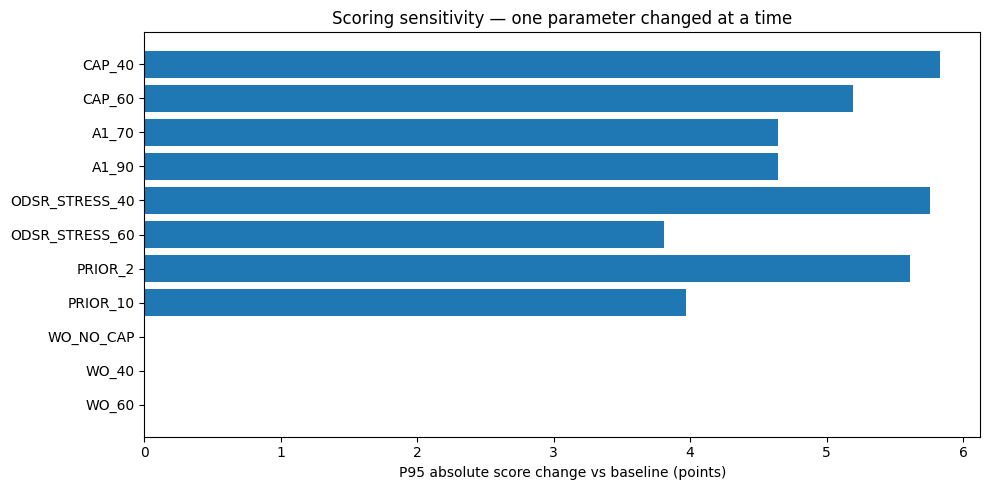

In [20]:
# Bảng xếp hạng mô tả sai số theo trường hợp cố ý che một trụ cột.
mask_rank=mask_report.sort_values(['MASKED_PILLAR','MAE'])
display(mask_rank[['MASKED_PILLAR','METHOD','MAE','P90_ABS_ERROR','PCT_BAND_CHANGED']].round(3))
print('GROUP_MEDIAN là chiến lược triển khai V2 đã chốt; bảng trên dùng để đánh giá, không tự động tối ưu lại.')
view=sensitivity[(sensitivity.SCOPE=='ALL_SCORED') & (sensitivity.SCENARIO!='BASELINE')]
fig,ax=plt.subplots(figsize=(10,5))
ax.barh(view.SCENARIO,view.P95_ABS_DELTA)
ax.set(xlabel='P95 absolute score change vs baseline (points)',
       title='Scoring sensitivity — one parameter changed at a time')
ax.invert_yaxis();fig.tight_layout()
fig.savefig(FIGURES/'02_sensitivity_score_shift.png',dpi=170)
plt.show()

## 18 — 4.3B: Kiểm thử cap và các giới hạn công thức

In [21]:
before=FHS_BASE
cap_rows=[]
for limit in (100.,60.,50.,40.):
    s=wo_cap(before,WO,limit)
    impacted=np.isfinite(before)&WO&(s<before-1e-8)
    shift=np.digitize(np.nan_to_num(before[impacted]),CFG['diagnostic_score_bands'][1:-1]) !=           np.digitize(np.nan_to_num(s[impacted]),CFG['diagnostic_score_bands'][1:-1])
    cap_rows.append({'CAP':limit,'WO_ALL':int(WO.sum()),'WO_WITH_FHS':int((WO&np.isfinite(before)).sum()),
                     'WO_NO_FHS':int((WO&~np.isfinite(before)).sum()),
                     'CUSTOMERS_ACTUALLY_CAPPED':int(impacted.sum()),
                     'AVG_SCORE_REDUCTION_IF_CAPPED':float((before[impacted]-s[impacted]).mean()) if impacted.any() else 0.,
                     'PCT_BAND_CHANGED_IF_CAPPED':float(100*shift.mean()) if impacted.any() else 0.})
cap_report=pd.DataFrame(cap_rows)
cap_report.to_csv(TABLES/'09_written_off_cap_stress.csv',index=False,encoding='utf-8-sig')
display(cap_report.round(2))
assert a1_score([.10,.50]).tolist()==[100.,0.]
assert np.all(np.diff(p1_score(np.arange(11),np.full(11,10)))<=1e-10)
assert np.all(wo_cap([30.,70.,95.],[True,True,True],40.)==[30.,40.,40.])
assert np.isnan(FHS[~(ci|pi)]).all()
assert np.all((FHS[np.isfinite(FHS)]>=0)&(FHS[np.isfinite(FHS)]<=100))
print('PASS: range, eligibility, monotonicity, cap boundary, missing-pillar handling.')

,CAP,WO_ALL,WO_WITH_FHS,WO_NO_FHS,CUSTOMERS_ACTUALLY_CAPPED,AVG_SCORE_REDUCTION_IF_CAPPED,PCT_BAND_CHANGED_IF_CAPPED
0,100.0,13319,13319,0,0,0.00,0.00
1,60.0,13319,13319,0,5779,12.33,8.84
2,50.0,13319,13319,0,7882,17.21,73.32
3,40.0,13319,13319,0,13312,18.72,43.41


PASS: range, eligibility, monotonicity, cap boundary, missing-pillar handling.


## 19 — Dashboard-ready summary & provenance

In [22]:
dashboard=pd.DataFrame([
 {'METRIC':'ALL_CUSTOMERS','VALUE':len(df)},
 {'METRIC':'FHS_NUMERIC','VALUE':int(np.isfinite(FHS).sum())},
 {'METRIC':'FULL','VALUE':int((ci&pi).sum())},
 {'METRIC':'PAYMENT_IMPUTED','VALUE':int(m_p.sum())},
 {'METRIC':'CAPACITY_IMPUTED','VALUE':int(m_c.sum())},
 {'METRIC':'NO_EVIDENCE','VALUE':int((~ci&~pi).sum())},
 {'METRIC':'WRITTEN_OFF_ALL','VALUE':int(WO.sum())},
 {'METRIC':'WRITTEN_OFF_WITH_FHS','VALUE':int((WO&np.isfinite(FHS)).sum())},
 {'METRIC':'INCOME_MONTHLY_CONFIRMED','VALUE':int(df.INCOME_MONTHLY_CONFIRMED.sum())},
])
dashboard.to_csv(TABLES/'10_summary_kpis.csv',index=False,encoding='utf-8-sig')
(OUT/'validation_methodology.txt').write_text(
    'FHS is a descriptive, proxy-based, explainable score, not a probability of default.\n'
    'Missing one pillar: group product/cohort median when enough reference observations, '
    'otherwise product/global median. Both absent => NULL. Observed pillar scores stay NULL if absent.\n'
    'Masked validation uses customer-level FULL holdout, with median trained on training only. '
    'Simulation does not prove performance on MNAR missingness.\n'
    'Score bands are diagnostics, not approved business segments. '
    'WO cap is business policy hypothesis; no claim of predictive validity.\n'
    'Income periodicity, payment event timing, other-lender debt are unverified.\n',
    encoding='utf-8')
display(dashboard)
print('OUTPUT FOLDER:',OUT)
print('MAIN CSV:',TARGET)
print('Reports: 01–10 in /tables ; Figures in /figures ; Config: scoring_parameters_v2.json')

,METRIC,VALUE
0,ALL_CUSTOMERS,1000528
1,FHS_NUMERIC,762665
2,FULL,471605
3,PAYMENT_IMPUTED,119091
4,CAPACITY_IMPUTED,171969
5,NO_EVIDENCE,237863
6,WRITTEN_OFF_ALL,13319
7,WRITTEN_OFF_WITH_FHS,13319
8,INCOME_MONTHLY_CONFIRMED,0


OUTPUT FOLDER: C:\Users\nguyen\Desktop\BI_r2\BI10_ROUND02_DATASET\C1_STEP4_V2_OUTPUT\run_20261018_113802_840b33
MAIN CSV: C:\Users\nguyen\Desktop\BI_r2\BI10_ROUND02_DATASET\C1_STEP4_V2_OUTPUT\run_20261018_113802_840b33\tables\02_customer_fhs_v2.csv
Reports: 01–10 in /tables ; Figures in /figures ; Config: scoring_parameters_v2.json


### Cơ sở và giới hạn phương pháp
- **A1:** tổng `ANNUITY` Active / `income_candidate` (chỉ là ODSR **proxy** khi chưa xác nhận cùng kỳ). Ngưỡng 10%–50% là giả thuyết thiết kế, không phải ngưỡng ngân hàng.
- **A2:** Thu nhập trừ trả góp Active; chuẩn hóa theo P10–P90 từ khách hàng đủ điều kiện để giảm ảnh hưởng outlier. Chưa trừ sinh hoạt phí.
- **P1:** Beta-binomial-style shrinkage với prior rate trên mẫu resolved-status proxy; `k=5` là tham số kiểm tra độ nhạy, không phải xác suất default. Số kỳ/case quan sát vừa ảnh hưởng ước lượng vừa ảnh hưởng độ tin cậy — xem bảng `06b_*`.
- **P3:** `Written off` là dấu hiệu nghiêm trọng; cap là quy tắc điều hành giả thuyết, phải kiểm tra `09_written_off_cap_stress.csv`.
- **Imputation:** median học từ khách hàng có score quan sát hợp lệ. Group Product/Cohort chỉ khả thi khi nguồn nhóm hiện hữu và đủ 200 hồ sơ; Payment-only thiếu thu nhập thường fallback GLOBAL. Đánh giá che trụ cột trên holdout không chứng minh dữ liệu thiếu thực tế là Missing At Random.
- **Cả hai trụ cột thiếu:** giữ `FINANCIAL_HEALTH_SCORE=NULL` và `NO_EVIDENCE` vì không có cơ sở xếp hạng. Điểm có bù phải hiển thị `SCORE_EVIDENCE_FLAG` khi so sánh.
- **V2 ≠ PD model:** Không coi FHS là xác suất vỡ nợ, chưa hiệu chuẩn theo kết cục tương lai; không tuyên bố công thức là FICO/CIC hoặc tuân thủ quy định ngân hàng.